In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

# Make the project root available for imports
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_processing import (
    prepare_temperature_data,
    add_time_gap,
    identify_continuous_blocks,
    summarise_blocks,
    extract_environmental_variables
)

from src.interpolation import (
    create_missing_gap,
    linear_interpolation,
    cubic_spline_interpolation
)

from src.ml_model import (
    train_linear_regression,
    predict_with_regression
)

from src.evaluation import (
    calculate_errors,
    evaluate_missing_gap,
    validate_multiple_blocks,
    summarise_validation,
    evaluate_three_methods,
    validate_three_methods,
    evaluate_cross_variable_reconstruction,
    validate_cross_variable_methods
)

print("Project root:", project_root)
print("Environment ready")

Project root: /Users/ben/Desktop/MMA3001 project/MMA3001-Occupancy-Prediction
Environment ready


In [2]:
import os
print(os.getcwd())

/Users/ben/Desktop/MMA3001 project/MMA3001-Occupancy-Prediction/notebooks


In [3]:
env = pd.read_csv("../Data/raw/5EnvSensor_MayToDec2024_180kRows.csv")

env.head()

,id,sensorid,devicetype,jsondata,status,processing_errors,createdate,processdate
0,2,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 03:11:58.210358+11,2024-02-29 03:11:58.210358+11
1,4,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:08.833822+11,2024-02-29 17:09:08.833822+11
2,5,6012002000326,env,"[{""values"": [{""time"": 1702270857, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:12.444245+11,2024-02-29 17:09:12.444245+11
3,16,6012002000777,env,"[{""values"": [{""time"": 1683326565, ""value"": 4.1...",Processed,NaN,2024-02-29 17:10:24.443407+11,2024-02-29 17:10:24.443407+11
4,24,6012002000869,env,"[{""values"": [{""time"": 1709186696, ""value"": 4.1...",Processed,NaN,2024-02-29 17:11:11.348578+11,2024-02-29 17:11:11.348578+11


In [4]:
print("Dataset shape:", env.shape)

print("\nColumns:")
print(env.columns)

print("\nData types:")
print(env.dtypes)

Dataset shape: (179447, 8)

Columns:
Index(['id', 'sensorid', 'devicetype', 'jsondata', 'status',
       'processing_errors', 'createdate', 'processdate'],
      dtype='object')

Data types:
id                     int64
sensorid               int64
devicetype            object
jsondata              object
status                object
processing_errors    float64
createdate            object
processdate           object
dtype: object


In [5]:
print(env["jsondata"].iloc[0])

[{"values": [{"time": 1702273965, "value": 4.1875}], "variable": {"id": 66, "name": "Battery", "unit": "V", "source": 0, "structure": 32834}}, {"values": [{"time": 1702273965, "value": 603}], "variable": {"id": 67, "name": "Carbon dioxide", "unit": "ppm", "source": 0, "structure": 32835}}, {"values": [{"time": 1702273965, "value": 66}], "variable": {"id": 72, "name": "Humidity", "unit": "HR%", "source": 0, "structure": 32840}}, {"values": [{"time": 1702273965, "value": 6}], "variable": {"id": 70, "name": "Formaldehyde", "unit": "µg/m3", "source": 0, "structure": 32847}}, {"values": [{"time": 1702273965, "value": 1011}], "variable": {"id": 80, "name": "Pressure", "unit": "mb", "source": 0, "structure": 32848}}, {"values": [{"time": 1702273965, "value": 23.8}], "variable": {"id": 84, "name": "Temperature", "unit": "°C", "source": 0, "structure": 32852}}, {"values": [{"time": 1702273965, "value": 14}], "variable": {"id": 99, "name": "Light Volatile Organic Compounds", "unit": "ppb", "sour

In [6]:
print("Number of sensors:", env["sensorid"].nunique())

print("\nSensor IDs:")
print(env["sensorid"].unique())

Number of sensors: 5

Sensor IDs:
[6012002000241 6012002000326 6012002000777 6012002000869 6012002000227]


In [7]:
sensor_id = 6012002000869

sensor = env[env["sensorid"] == sensor_id].copy()

print(sensor.shape)
sensor.head()

(29341, 8)


,id,sensorid,devicetype,jsondata,status,processing_errors,createdate,processdate
4,24,6012002000869,env,"[{""values"": [{""time"": 1709186696, ""value"": 4.1...",Processed,NaN,2024-02-29 17:11:11.348578+11,2024-02-29 17:11:11.348578+11
8,58,6012002000869,env,"[{""values"": [{""time"": 1709187297, ""value"": 4.1...",Processed,NaN,2024-02-29 17:24:31.400806+11,2024-02-29 17:24:31.400806+11
12,92,6012002000869,env,"[{""values"": [{""time"": 1709188497, ""value"": 4.1...",Processed,NaN,2024-02-29 17:38:05.661335+11,2024-02-29 17:38:05.661335+11
16,126,6012002000869,env,"[{""values"": [{""time"": 1709189097, ""value"": 4.1...",Processed,NaN,2024-02-29 17:51:24.418554+11,2024-02-29 17:51:24.418554+11
20,160,6012002000869,env,"[{""values"": [{""time"": 1709189697, ""value"": 4.1...",Processed,NaN,2024-02-29 18:04:45.909552+11,2024-02-29 18:04:45.909552+11


In [8]:
temperature_data = prepare_temperature_data(
    env,
    sensor_id
)

temperature_data.head()

,time,temperature
0,2024-02-29 06:04:56,24.3
1,2024-02-29 06:14:57,24.0
2,2024-02-29 06:34:57,23.8
3,2024-02-29 06:44:57,23.8
4,2024-02-29 06:54:57,23.8


In [9]:
temp_data = temperature_data.copy()

temp_data = add_time_gap(
    temp_data
)

temp_data = identify_continuous_blocks(
    temp_data,
    expected_minutes=10,
    tolerance_seconds=5
)

block_summary = summarise_blocks(
    temp_data
)

block_summary.head()

,start,end,measurements,duration
block,,,,
157,2024-03-04 16:24:59,2024-03-05 03:14:59,66,0 days 10:50:00
196,2024-03-06 13:04:56,2024-03-06 23:44:56,65,0 days 10:40:00
193,2024-03-06 02:24:59,2024-03-06 11:24:58,55,0 days 08:59:59
1279,2024-05-31 17:15:36,2024-05-31 19:35:36,15,0 days 02:20:00
1277,2024-05-31 12:05:35,2024-05-31 14:25:37,15,0 days 02:20:02


In [10]:
best_block = block_summary.index[0]

ground_truth = (
    temp_data[
        temp_data["block"] == best_block
    ][["time", "temperature"]]
    .reset_index(drop=True)
    .copy()
)

print("Selected block:", best_block)
print("Measurements:", len(ground_truth))

ground_truth.head()

Selected block: 157
Measurements: 66


,time,temperature
0,2024-03-04 16:24:59,22.0
1,2024-03-04 16:34:57,22.0
2,2024-03-04 16:44:58,21.8
3,2024-03-04 16:54:58,21.8
4,2024-03-04 17:04:59,21.8


In [12]:
print("Number of temperature measurements:", len(temp_data))

print("\nMissing values:")
print(temp_data.isnull().sum())

print("\nDuplicate times:")
print(temp_data["time"].duplicated().sum())

print("\nTime range:")
print(temp_data["time"].min())
print(temp_data["time"].max())

Number of temperature measurements: 13800

Missing values:
time           0
temperature    0
time_gap       1
regular_gap    0
new_block      0
block          0
dtype: int64

Duplicate times:
0

Time range:
2024-02-29 06:04:56
2024-06-13 17:45:44


In [13]:
temp_data["time_gap"] = temp_data["time"].diff()

print(temp_data["time_gap"].value_counts().head(10))

time_gap
0 days 00:10:00    9191
0 days 00:10:01    1309
0 days 00:09:59    1256
0 days 00:20:00     899
0 days 00:09:58     305
0 days 00:10:02     286
0 days 00:20:01     194
0 days 00:19:59     173
0 days 00:20:02      58
0 days 00:19:58      49
Name: count, dtype: int64


(803, 6)


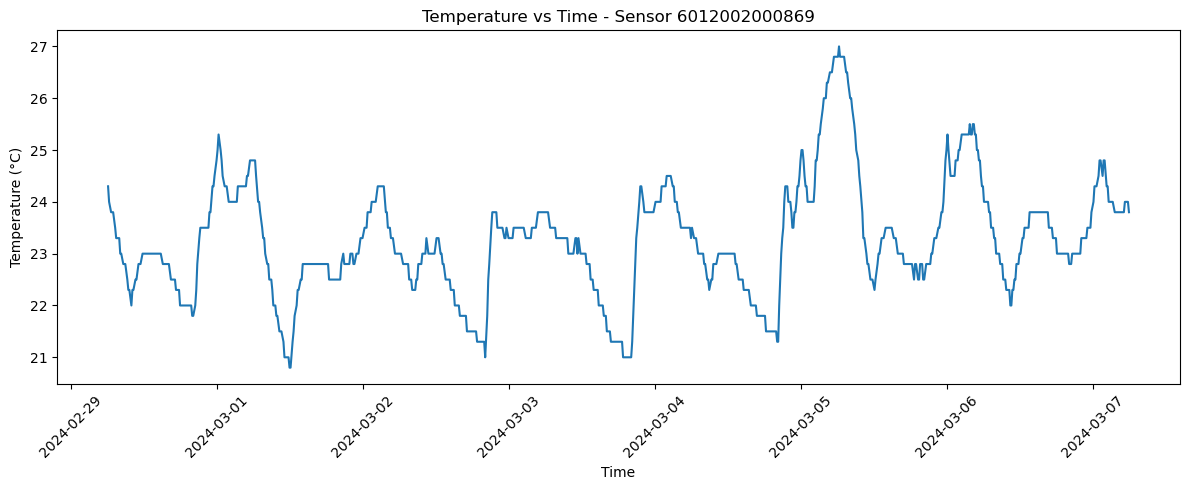

In [14]:
start_time = temp_data["time"].min()
end_time = start_time + pd.Timedelta(days=7)

temp_week = temp_data[
    (temp_data["time"] >= start_time) &
    (temp_data["time"] <= end_time)
].copy()

print(temp_week.shape)
plt.figure(figsize=(12, 5))

plt.plot(
    temp_week["time"],
    temp_week["temperature"]
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("Temperature vs Time - Sensor 6012002000869")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [15]:
duplicate_count = temp_data["time"].duplicated().sum()

print(
    "Duplicate timestamps after cleaning:",
    duplicate_count
)

Duplicate timestamps after cleaning: 0


In [16]:
print("Raw sensor rows:", len(sensor))
print("Clean temperature rows:", len(temp_data))
print(
    "Duplicate timestamps after cleaning:",
    temp_data["time"].duplicated().sum()
)

print("\nMissing values:")
print(
    temp_data[
        ["time", "temperature"]
    ].isnull().sum()
)

Raw sensor rows: 29341
Clean temperature rows: 13800
Duplicate timestamps after cleaning: 0

Missing values:
time           0
temperature    0
dtype: int64


In [17]:
print(
    temp_data["time_gap"]
    .value_counts()
    .head(10)
)

gap_seconds = (
    temp_data["time_gap"]
    .dt.total_seconds()
)

regular_gap = gap_seconds.between(
    595,
    605
)

print(
    "\nRegular ~10 minute intervals:",
    regular_gap.sum()
)

print(
    "Percentage:",
    round(
        regular_gap.mean() * 100,
        2
    ),
    "%"
)

time_gap
0 days 00:10:00    9191
0 days 00:10:01    1309
0 days 00:09:59    1256
0 days 00:20:00     899
0 days 00:09:58     305
0 days 00:10:02     286
0 days 00:20:01     194
0 days 00:19:59     173
0 days 00:20:02      58
0 days 00:19:58      49
Name: count, dtype: int64

Regular ~10 minute intervals: 12398
Percentage: 89.84 %


Selected block: 157
Number of measurements: 66
Start: 2024-03-04 16:24:59
End: 2024-03-05 03:14:59


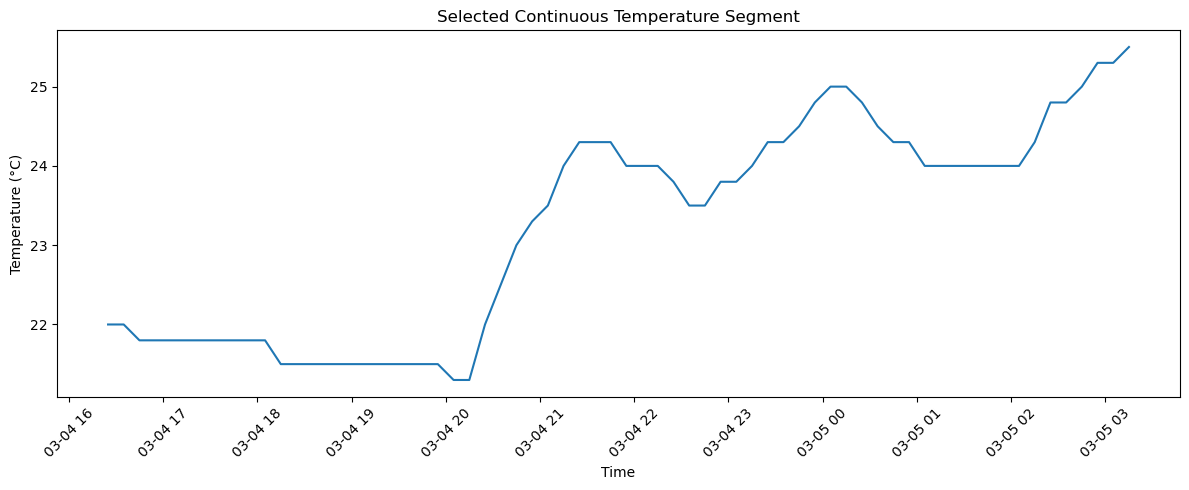

In [18]:
best_block = block_summary.index[0]

ground_truth = (
    temp_data[
        temp_data["block"] == best_block
    ][["time", "temperature"]]
    .reset_index(drop=True)
    .copy()
)

print("Selected block:", best_block)
print("Number of measurements:", len(ground_truth))
print("Start:", ground_truth["time"].min())
print("End:", ground_truth["time"].max())

ground_truth.head()
plt.figure(figsize=(12, 5))

plt.plot(
    ground_truth["time"],
    ground_truth["temperature"]
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("Selected Continuous Temperature Segment")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [19]:
import numpy as np

In [20]:
# Create the first artificial missing gap
gap_size = 3

start_idx = (
    len(ground_truth) // 2
    - gap_size // 2
)

experiment = create_missing_gap(
    ground_truth[["time", "temperature"]],
    gap_size=gap_size,
    start_idx=start_idx
)

experiment.iloc[
    start_idx - 3:
    start_idx + gap_size + 3
]

,time,temperature,actual
29,2024-03-04 21:14:59,24.0,24.0
30,2024-03-04 21:24:59,24.3,24.3
31,2024-03-04 21:34:58,24.3,24.3
32,2024-03-04 21:44:58,NaN,24.3
33,2024-03-04 21:54:58,NaN,24.0
34,2024-03-04 22:04:59,NaN,24.0
35,2024-03-04 22:14:59,24.0,24.0
36,2024-03-04 22:24:59,23.8,23.8
37,2024-03-04 22:34:59,23.5,23.5


In [21]:
linear_result = linear_interpolation(
    experiment.copy()
)

cubic_result = cubic_spline_interpolation(
    experiment.copy()
)

missing_mask = experiment["temperature"].isna()

comparison = experiment.loc[
    missing_mask,
    ["time", "actual"]
].copy()

comparison["linear"] = linear_result.loc[
    missing_mask,
    "linear"
]

comparison["cubic"] = cubic_result.loc[
    missing_mask,
    "cubic"
]

comparison

,time,actual,linear,cubic
32,2024-03-04 21:44:58,24.3,24.225031,24.248513
33,2024-03-04 21:54:58,24.0,24.150062,24.193456
34,2024-03-04 22:04:59,24.0,24.074969,24.116575


In [22]:
linear_mae, linear_rmse = calculate_errors(
    comparison["actual"],
    comparison["linear"]
)

cubic_mae, cubic_rmse = calculate_errors(
    comparison["actual"],
    comparison["cubic"]
)

results = pd.DataFrame({
    "Method": [
        "Linear",
        "Cubic Spline"
    ],
    "MAE (°C)": [
        linear_mae,
        cubic_mae
    ],
    "RMSE (°C)": [
        linear_rmse,
        cubic_rmse
    ]
})

results

,Method,MAE (°C),RMSE (°C)
0,Linear,0.100000,0.106081
1,Cubic Spline,0.120506,0.133749


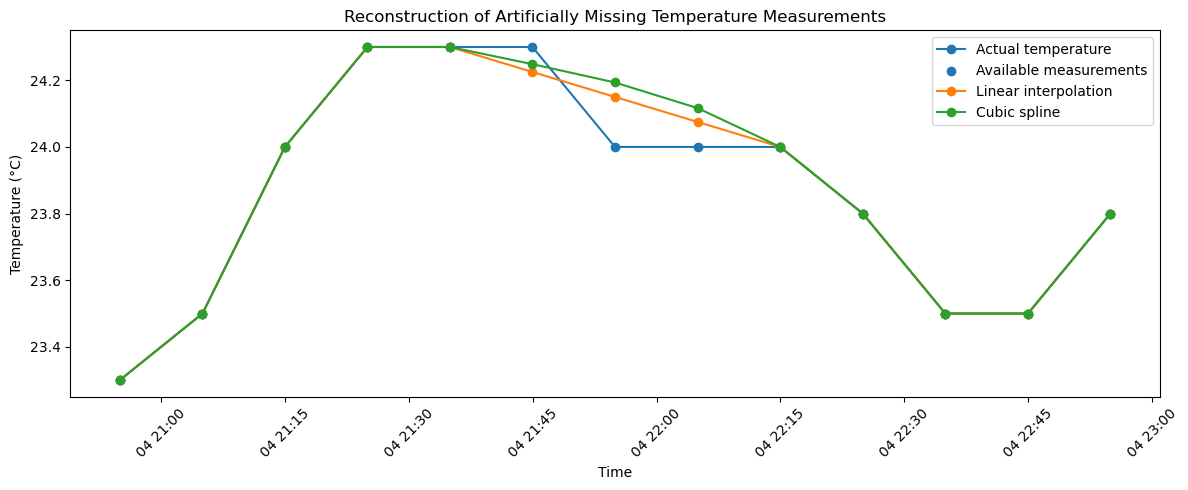

In [23]:
missing_mask = experiment["temperature"].isna()

missing_positions = np.where(
    missing_mask.to_numpy()
)[0]

window_start = max(
    missing_positions[0] - 5,
    0
)

window_end = min(
    missing_positions[-1] + 6,
    len(experiment)
)

plot_data = experiment.copy()

plot_data["linear"] = linear_result["linear"]
plot_data["cubic"] = cubic_result["cubic"]

plot_data = plot_data.iloc[
    window_start:window_end
].copy()

plt.figure(figsize=(12, 5))

plt.plot(
    plot_data["time"],
    plot_data["actual"],
    marker="o",
    label="Actual temperature"
)

plt.scatter(
    plot_data["time"],
    plot_data["temperature"],
    label="Available measurements"
)

plt.plot(
    plot_data["time"],
    plot_data["linear"],
    marker="o",
    label="Lin" \
    "ear interpolation"
)
plt.plot(
    plot_data["time"],
    plot_data["cubic"],
    marker="o",
    label="Cubic spline"
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("Reconstruction of Artificially Missing Temperature Measurements")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    "../results/figures/reconstruction_example.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
top_blocks = (
    block_summary
    .head(3)
    .index
    .tolist()
)

gap_sizes = [1, 3, 6, 12]

multi_validation = validate_multiple_blocks(
    temp_data,
    block_ids=top_blocks,
    gap_sizes=gap_sizes,
    positions_per_gap=5
)

print(
    "Selected blocks:",
    top_blocks
)

print(
    "Total experiments:",
    len(multi_validation)
)

multi_validation.head()

Selected blocks: [157, 196, 193]
Total experiments: 60


,gap_size,start_idx,linear_mae,linear_rmse,cubic_mae,cubic_rmse,block
0,1,5,0.00,0.00,0.002643,0.002643,157
1,1,18,0.00,0.00,0.002733,0.002733,157
2,1,32,0.15,0.15,0.159374,0.159374,157
3,1,46,0.10,0.10,0.007228,0.007228,157
4,1,60,0.25,0.25,0.205517,0.205517,157


In [25]:
multi_summary = summarise_validation(
    multi_validation
)

multi_summary

,n_tests,linear_mae_mean,linear_mae_std,linear_rmse_mean,linear_rmse_std,cubic_mae_mean,cubic_mae_std,cubic_rmse_mean,cubic_rmse_std
gap_size,,,,,,,,,
1,15,0.076667,0.075277,0.076667,0.075277,0.078649,0.074921,0.078649,0.074921
3,15,0.076677,0.065108,0.084705,0.074358,0.108640,0.069849,0.119482,0.076219
6,15,0.137453,0.071917,0.156580,0.077941,0.192005,0.137700,0.218580,0.142200
12,15,0.237131,0.216897,0.277215,0.246427,0.218769,0.214474,0.253208,0.224939


Text(0.5, 1.0, 'Reconstruction Error Across Multiple Temperature Segments')

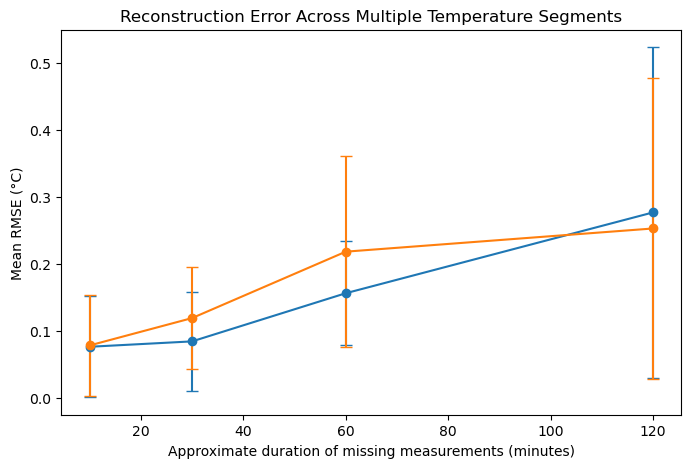

In [26]:
plot_multi = multi_summary.reset_index().copy()

plot_multi["missing_minutes"] = (
    plot_multi["gap_size"] * 10
)

plt.figure(figsize=(8, 5))

plt.errorbar(
    plot_multi["missing_minutes"],
    plot_multi["linear_rmse_mean"],
    yerr=plot_multi["linear_rmse_std"],
    marker="o",
    capsize=4,
    label="Linear interpolation"
)

plt.errorbar(
    plot_multi["missing_minutes"],
    plot_multi["cubic_rmse_mean"],
    yerr=plot_multi["cubic_rmse_std"],
    marker="o",
    capsize=4,
    label="Cubic spline"
)

plt.xlabel(
    "Approximate duration of missing measurements (minutes)"
)

plt.ylabel("Mean RMSE (°C)")

plt.title(
    "Reconstruction Error Across Multiple Temperature Segments"
)



In [27]:
final_results = multi_summary.reset_index().copy()

final_results["missing_minutes"] = (
    final_results["gap_size"] * 10
)

final_results = final_results[
    [
        "gap_size",
        "missing_minutes",
        "n_tests",
        "linear_mae_mean",
        "linear_rmse_mean",
        "cubic_mae_mean",
        "cubic_rmse_mean"
    ]
]

final_results.round(4)

,gap_size,missing_minutes,n_tests,linear_mae_mean,linear_rmse_mean,cubic_mae_mean,cubic_rmse_mean
0,1,10,15,0.0767,0.0767,0.0786,0.0786
1,3,30,15,0.0767,0.0847,0.1086,0.1195
2,6,60,15,0.1375,0.1566,0.1920,0.2186
3,12,120,15,0.2371,0.2772,0.2188,0.2532


In [28]:
tables_dir = project_root / "results" / "tables"
figures_dir = project_root / "results" / "figures"

tables_dir.mkdir(
    parents=True,
    exist_ok=True
)

figures_dir.mkdir(
    parents=True,
    exist_ok=True
)

final_results.to_csv(
    tables_dir / "interpolation_validation_results.csv",
    index=False
)

print("Results saved successfully")

Results saved successfully


In [29]:
import sys
from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_processing import (
    prepare_temperature_data,
    add_time_gap,
    identify_continuous_blocks,
    summarise_blocks
)


In [30]:
sensor_id = 6012002000869

clean_test = prepare_temperature_data(
    env,
    sensor_id
)

clean_test = add_time_gap(clean_test)

clean_test = identify_continuous_blocks(
    clean_test,
    expected_minutes=10,
    tolerance_seconds=5
)

block_test = summarise_blocks(clean_test)

print("Clean measurements:", len(clean_test))
block_test.head()

Clean measurements: 13800


,start,end,measurements,duration
block,,,,
157,2024-03-04 16:24:59,2024-03-05 03:14:59,66,0 days 10:50:00
196,2024-03-06 13:04:56,2024-03-06 23:44:56,65,0 days 10:40:00
193,2024-03-06 02:24:59,2024-03-06 11:24:58,55,0 days 08:59:59
1279,2024-05-31 17:15:36,2024-05-31 19:35:36,15,0 days 02:20:00
1277,2024-05-31 12:05:35,2024-05-31 14:25:37,15,0 days 02:20:02


In [31]:
from src.interpolation import (
    create_missing_gap,
    linear_interpolation,
    cubic_spline_interpolation
)

print("interpolation imported successfully")

interpolation imported successfully


In [33]:
ground_truth_test = (
    clean_test[clean_test["block"] == 157]
    [["time", "temperature"]]
    .reset_index(drop=True)
    .copy()
)

experiment_test = create_missing_gap(
    ground_truth_test,
    gap_size=3,
    start_idx=32
)

experiment_test = linear_interpolation(
    experiment_test
)

experiment_test = cubic_spline_interpolation(
    experiment_test
)

experiment_test.loc[
    32:34,
    ["time", "actual", "temperature", "linear", "cubic"]
]

,time,actual,temperature,linear,cubic
32,2024-03-04 21:44:58,24.3,NaN,24.225031,24.248513
33,2024-03-04 21:54:58,24.0,NaN,24.150062,24.193456
34,2024-03-04 22:04:59,24.0,NaN,24.074969,24.116575


## Multivariable Sensor Analysis

Pressure and humidity are investigated as additional environmental variables
that may contain useful information for reconstructing missing temperature
measurements.

In [34]:
multi_data = sensor["jsondata"].apply(
    extract_environmental_variables
)

multi_data.head()

,timestamp,temperature,humidity,pressure
4,1.709187e+09,24.3,56.0,1010.0
8,1.709187e+09,24.0,56.0,1010.0
12,1.709188e+09,23.8,56.0,1010.0
16,1.709189e+09,23.8,56.0,1010.0
20,1.709190e+09,23.8,57.0,1010.0


In [35]:
# Rebuild multivariable sensor data from the raw JSON
multi_data = sensor["jsondata"].apply(
    extract_environmental_variables
)

# Convert timestamp to datetime
multi_data["time"] = pd.to_datetime(
    multi_data["timestamp"],
    unit="s"
)

# Convert environmental variables to numeric values
for col in ["temperature", "humidity", "pressure"]:
    multi_data[col] = pd.to_numeric(
        multi_data[col],
        errors="coerce"
    )

# Keep only the variables required for the analysis
multi_data = multi_data[
    ["time", "temperature", "humidity", "pressure"]
].copy()

multi_data.head()

,time,temperature,humidity,pressure
4,2024-02-29 06:04:56,24.3,56.0,1010.0
8,2024-02-29 06:14:57,24.0,56.0,1010.0
12,2024-02-29 06:34:57,23.8,56.0,1010.0
16,2024-02-29 06:44:57,23.8,56.0,1010.0
20,2024-02-29 06:54:57,23.8,57.0,1010.0


In [36]:
print("Original rows:", len(multi_data))

print("\nMissing values:")
print(multi_data.isnull().sum())

Original rows: 29341

Missing values:
time           0
temperature    0
humidity       0
pressure       0
dtype: int64


In [37]:
duplicate_check = (
    multi_data
    .groupby("time")
    [["temperature", "humidity", "pressure"]]
    .nunique()
)

conflicts = duplicate_check[
    (duplicate_check["temperature"] > 1) |
    (duplicate_check["humidity"] > 1) |
    (duplicate_check["pressure"] > 1)
]

print(
    "Conflicting duplicate timestamps:",
    len(conflicts)
)

Conflicting duplicate timestamps: 0


In [38]:
multi_clean = (
    multi_data
    .drop_duplicates(
        subset="time",
        keep="first"
    )
    .dropna(
        subset=[
            "temperature",
            "humidity",
            "pressure"
        ]
    )
    .sort_values("time")
    .reset_index(drop=True)
)

print("Clean rows:", len(multi_clean))

multi_clean.head()

Clean rows: 13800


,time,temperature,humidity,pressure
0,2024-02-29 06:04:56,24.3,56.0,1010.0
1,2024-02-29 06:14:57,24.0,56.0,1010.0
2,2024-02-29 06:34:57,23.8,56.0,1010.0
3,2024-02-29 06:44:57,23.8,56.0,1010.0
4,2024-02-29 06:54:57,23.8,57.0,1010.0


In [39]:
multi_clean[["temperature", "humidity", "pressure"]].describe().round(2)

,temperature,humidity,pressure
count,13800.00,13800.00,13800.00
mean,23.09,45.03,1017.83
std,1.16,7.39,5.66
min,19.00,26.00,1002.00
25%,22.50,40.00,1014.00
50%,23.30,45.00,1019.00
75%,23.80,49.00,1022.00
max,28.50,75.00,1028.00


## Regression Model Selection

To investigate whether other environmental measurements can help reconstruct
missing temperature data, three linear regression models are compared:

1. Humidity → Temperature
2. Pressure → Temperature
3. Humidity + Pressure → Temperature

Because the sensor measurements are time-series data, a chronological
80/20 train-test split is used. The earlier 80% of the measurements are used
to train the models, while the final 20% are kept as unseen test data.

The three regression models are retained for comparison to investigate whether humidity, pressure, or their combination provides useful information for reconstructing missing temperature measurements.

In [40]:
# Ensure the data are in chronological order
multi_clean = (
    multi_clean
    .sort_values("time")
    .reset_index(drop=True)
)

# Chronological 80/20 train-test split
split_index = int(len(multi_clean) * 0.8)

train_data = multi_clean.iloc[:split_index].copy()
test_data = multi_clean.iloc[split_index:].copy()

print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))

print(
    "Training period:",
    train_data["time"].min(),
    "to",
    train_data["time"].max()
)

print(
    "Testing period:",
    test_data["time"].min(),
    "to",
    test_data["time"].max()
)

Training rows: 11040
Testing rows: 2760
Training period: 2024-02-29 06:04:56 to 2024-05-24 06:05:37
Testing period: 2024-05-24 06:15:37 to 2024-06-13 17:45:44


In [42]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def evaluate_regression_model(
    train_df,
    test_df,
    predictors,
    model_name
):
    """
    Train and evaluate a linear regression model
    for temperature prediction.
    """

    train_clean = train_df.dropna(
        subset=predictors + ["temperature"]
    )

    test_clean = test_df.dropna(
        subset=predictors + ["temperature"]
    )

    # Training data
    X_train = train_clean[predictors]
    y_train = train_clean["temperature"]

    # Unseen test data
    X_test = test_clean[predictors]
    y_test = test_clean["temperature"]

    # Train model
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Predict unseen temperature
    prediction = model.predict(X_test)

    # Evaluation metrics
    mae = mean_absolute_error(
        y_test,
        prediction
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            prediction
        )
    )

    r2 = r2_score(
        y_test,
        prediction
    )

    result = {
        "Model": model_name,
        "Predictors": " + ".join(predictors),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

    return model, result

In [43]:
# Humidity -> Temperature
humidity_model, humidity_result = evaluate_regression_model(
    train_data,
    test_data,
    predictors=["humidity"],
    model_name="Humidity only"
)

# Pressure -> Temperature
pressure_model, pressure_result = evaluate_regression_model(
    train_data,
    test_data,
    predictors=["pressure"],
    model_name="Pressure only"
)

# Humidity + Pressure -> Temperature
combined_model, combined_result = evaluate_regression_model(
    train_data,
    test_data,
    predictors=["humidity", "pressure"],
    model_name="Humidity + Pressure"
)

# Comparison table
regression_model_comparison = pd.DataFrame([
    humidity_result,
    pressure_result,
    combined_result
])

regression_model_comparison

,Model,Predictors,MAE,RMSE,R2
0,Humidity only,humidity,0.759534,1.105099,-0.066522
1,Pressure only,pressure,0.822548,1.123874,-0.103071
2,Humidity + Pressure,humidity + pressure,0.925719,1.269244,-0.406883


### Temperature Variation and Normalised Error

Absolute RMSE alone does not show whether an error is small relative to the
actual variation in temperature.

Therefore, the temperature range of the unseen test data is calculated and
the RMSE is normalised by this range:

NRMSE = RMSE / Temperature Range × 100%

This allows the reconstruction error to be interpreted relative to the
variation present in the measured temperature data.

In [44]:
# Temperature variation in the unseen test period
test_temperature = test_data["temperature"].dropna()

temperature_min = test_temperature.min()
temperature_max = test_temperature.max()
temperature_range = temperature_max - temperature_min
temperature_std = test_temperature.std()

print("Test temperature minimum:", temperature_min, "°C")
print("Test temperature maximum:", temperature_max, "°C")
print("Test temperature range:", temperature_range, "°C")
print("Test temperature standard deviation:", temperature_std, "°C")

Test temperature minimum: 19.5 °C
Test temperature maximum: 25.5 °C
Test temperature range: 6.0 °C
Test temperature standard deviation: 1.070273488631196 °C


In [45]:
# Add normalised RMSE to the regression comparison
regression_model_comparison["NRMSE (%)"] = (
    regression_model_comparison["RMSE"]
    / temperature_range
    * 100
)

regression_model_comparison

,Model,Predictors,MAE,RMSE,R2,NRMSE (%)
0,Humidity only,humidity,0.759534,1.105099,-0.066522,18.418312
1,Pressure only,pressure,0.822548,1.123874,-0.103071,18.731238
2,Humidity + Pressure,humidity + pressure,0.925719,1.269244,-0.406883,21.154068


In [46]:
# ============================================================
# Demonstration: artificially remove a section of temperature
# and reconstruct it using the trained regression models
# ============================================================

# Use a copy of the unseen test data
gap_demo = test_data.copy()

# Choose 12 consecutive measurements (~120 minutes)
gap_size = 12
start_idx = len(gap_demo) // 2

gap_index = gap_demo.index[start_idx:start_idx + gap_size]

# Save the true temperature before hiding it
actual_temperature = gap_demo.loc[gap_index, "temperature"].copy()

# Artificially remove temperature
gap_demo.loc[gap_index, "temperature"] = np.nan

# Predict missing temperature using Humidity only
humidity_prediction = humidity_model.predict(
    gap_demo.loc[gap_index, ["humidity"]]
)

# Predict missing temperature using Pressure only
pressure_prediction = pressure_model.predict(
    gap_demo.loc[gap_index, ["pressure"]]
)

# Predict missing temperature using Humidity + Pressure
combined_prediction = combined_model.predict(
    gap_demo.loc[gap_index, ["humidity", "pressure"]]
)

# Build comparison table
gap_regression_demo = pd.DataFrame({
    "Actual Temperature": actual_temperature.values,
    "Humidity only": humidity_prediction,
    "Pressure only": pressure_prediction,
    "Humidity + Pressure": combined_prediction
})

gap_regression_demo

,Actual Temperature,Humidity only,Pressure only,Humidity + Pressure
0,23.8,23.376379,23.395482,24.125426
1,23.8,23.376379,23.395482,24.125426
2,23.8,23.376379,23.395482,24.125426
3,23.8,23.376379,23.427648,24.186783
4,23.8,23.376379,23.395482,24.125426
5,23.8,23.376379,23.395482,24.125426
6,23.8,23.376379,23.395482,24.125426
7,23.8,23.376379,23.395482,24.125426
8,23.8,23.376379,23.395482,24.125426
9,23.8,23.376379,23.395482,24.125426


### Regression Model Comparison

The three models are compared using NRMSE so that the prediction error can
be interpreted relative to the temperature variation in the unseen test data.

Lower NRMSE indicates better temperature prediction performance.

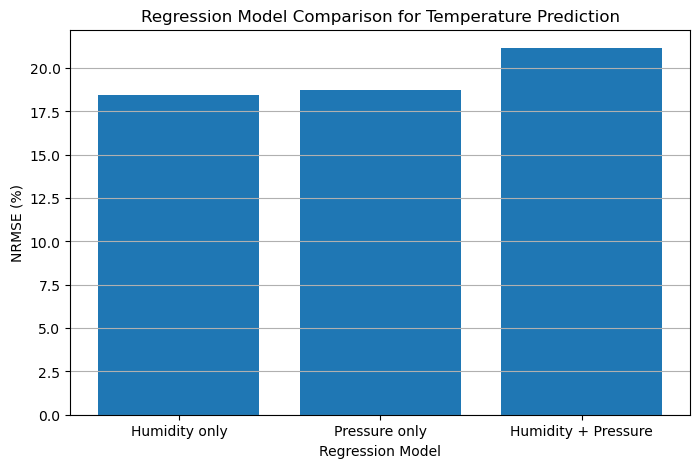

In [47]:
plt.figure(figsize=(8, 5))

plt.bar(
    regression_model_comparison["Model"],
    regression_model_comparison["NRMSE (%)"]
)

plt.ylabel("NRMSE (%)")
plt.xlabel("Regression Model")
plt.title("Regression Model Comparison for Temperature Prediction")

plt.grid(axis="y")
plt.show()

## Missing Temperature Reconstruction Validation

The final validation compares six reconstruction approaches using the same
artificially withheld temperature measurements from the unseen test period:

- Persistence baseline
- Linear interpolation
- Cubic spline interpolation
- Humidity-only regression
- Pressure-only regression
- Humidity + Pressure regression

Artificial missing windows are created using actual timestamps from the unseen test period. Only originally observed temperature measurements are withheld and evaluated against their ground truth.

In [48]:
# Prepare unseen test data for reconstruction validation

validation_data = (
    test_data
    .dropna(subset=[
        "time",
        "temperature",
        "humidity",
        "pressure"
    ])
    .sort_values("time")
    .reset_index(drop=True)
    .copy()
)

print("Validation rows:", len(validation_data))


Validation rows: 2760


### Artificial Missing Temperature Windows

Artificial missing-temperature windows are created within the unseen test
period using actual timestamps.

Four nominal outage durations are considered: 10, 30, 60 and 120 minutes.

Only originally observed temperature measurements are withheld and used as
ground truth. Naturally absent measurements are not included in error
calculations.

The same test windows will be used for all six reconstruction methods.

In [49]:
from src.validation import create_missing_windows

missing_windows = create_missing_windows(
    validation_data,
    gap_durations=(10, 30, 60, 120),
    n_tests=15
)

print("Number of windows:", len(missing_windows))
missing_windows.head()

Number of windows: 60


,duration_min,test_number,start_time,end_time,n_hidden
0,10,1,2024-05-24 06:55:37,2024-05-24 07:05:37,1
1,10,2,2024-05-25 17:35:35,2024-05-25 17:45:35,1
2,10,3,2024-05-27 04:15:35,2024-05-27 04:25:35,1
3,10,4,2024-05-28 15:15:36,2024-05-28 15:25:36,1
4,10,5,2024-05-30 01:55:35,2024-05-30 02:05:35,1


In [50]:
window_summary = (
    missing_windows
    .groupby("duration_min")
    .agg(
        n_tests=("test_number", "count"),
        min_hidden=("n_hidden", "min"),
        max_hidden=("n_hidden", "max"),
        mean_hidden=("n_hidden", "mean")
    )
    .reset_index()
)

window_summary

,duration_min,n_tests,min_hidden,max_hidden,mean_hidden
0,10,15,1,1,1.000000
1,30,15,2,3,2.733333
2,60,15,5,6,5.533333
3,120,15,11,11,11.000000


In [51]:
from src.validation import create_missing_windows
from pandas.testing import assert_frame_equal

# Generate windows using the new function
new_missing_windows = create_missing_windows(
    validation_data,
    gap_durations=(10, 30, 60, 120),
    n_tests=15
) 

# Verify that the refactored function gives identical results
assert_frame_equal(
    missing_windows.reset_index(drop=True),
    new_missing_windows.reset_index(drop=True)
)

print("Refactoring successful: results are identical.")
print("Number of windows:", len(new_missing_windows))

new_missing_windows.head()

Refactoring successful: results are identical.
Number of windows: 60


,duration_min,test_number,start_time,end_time,n_hidden
0,10,1,2024-05-24 06:55:37,2024-05-24 07:05:37,1
1,10,2,2024-05-25 17:35:35,2024-05-25 17:45:35,1
2,10,3,2024-05-27 04:15:35,2024-05-27 04:25:35,1
3,10,4,2024-05-28 15:15:36,2024-05-28 15:25:36,1
4,10,5,2024-05-30 01:55:35,2024-05-30 02:05:35,1


In [52]:
from src.validation import validate_reconstruction

reconstruction_results = validate_reconstruction(
    validation_data=validation_data,
    missing_windows=missing_windows,
    humidity_model=humidity_model,
    pressure_model=pressure_model,
    combined_model=combined_model,
    temperature_range=temperature_range
)

print("Number of evaluations:", len(reconstruction_results))
reconstruction_results.head(12)

Number of evaluations: 420


,duration_min,test_number,start_time,n_hidden,method,MAE,RMSE,NRMSE (%)
0,10,1,2024-05-24 06:55:37,1,Persistence,0.000000,0.000000,0.000000
1,10,1,2024-05-24 06:55:37,1,Linear,0.150000,0.150000,2.500000
2,10,1,2024-05-24 06:55:37,1,Cubic spline,0.169398,0.169398,2.823297
3,10,1,2024-05-24 06:55:37,1,Humidity regression,0.137583,0.137583,2.293052
4,10,1,2024-05-24 06:55:37,1,Pressure regression,0.022669,0.022669,0.377812
5,10,1,2024-05-24 06:55:37,1,Combined regression,0.138387,0.138387,2.306445
6,10,1,2024-05-24 06:55:37,1,Endpoint-constrained regression,0.150000,0.150000,2.500000
7,10,2,2024-05-25 17:35:35,1,Persistence,0.000000,0.000000,0.000000
8,10,2,2024-05-25 17:35:35,1,Linear,0.000000,0.000000,0.000000
9,10,2,2024-05-25 17:35:35,1,Cubic spline,0.024587,0.024587,0.409779


In [53]:
# ============================================================
# Final reconstruction performance summary
# ============================================================

final_summary = (
    reconstruction_results
    .groupby(["duration_min", "method"])
    .agg(
        n_tests=("RMSE", "count"),
        MAE_mean=("MAE", "mean"),
        RMSE_mean=("RMSE", "mean"),
        NRMSE_mean=("NRMSE (%)", "mean")
    )
    .reset_index()
)

final_summary = final_summary.round(4)

final_summary

,duration_min,method,n_tests,MAE_mean,RMSE_mean,NRMSE_mean
0,10,Combined regression,15,0.9272,0.9272,15.4526
1,10,Cubic spline,15,0.0787,0.0787,1.3119
2,10,Endpoint-constrained regression,15,0.0722,0.0722,1.2039
3,10,Humidity regression,15,0.7040,0.7040,11.7334
4,10,Linear,15,0.0733,0.0733,1.2216
5,10,Persistence,15,0.0733,0.0733,1.2222
6,10,Pressure regression,15,0.7149,0.7149,11.9157
7,30,Combined regression,15,0.9342,0.9397,15.6619
8,30,Cubic spline,15,0.0857,0.0959,1.5979
9,30,Endpoint-constrained regression,15,0.0823,0.0889,1.4825


### Final Reconstruction Method Comparison

The six reconstruction approaches are compared across four missing-data durations using the same artificially withheld temperature measurements.

Mean NRMSE is used to compare reconstruction accuracy relative to the observed temperature range in the unseen test period.

A persistence baseline is included to determine whether interpolation methods provide meaningful improvements over simply retaining the last known temperature value.

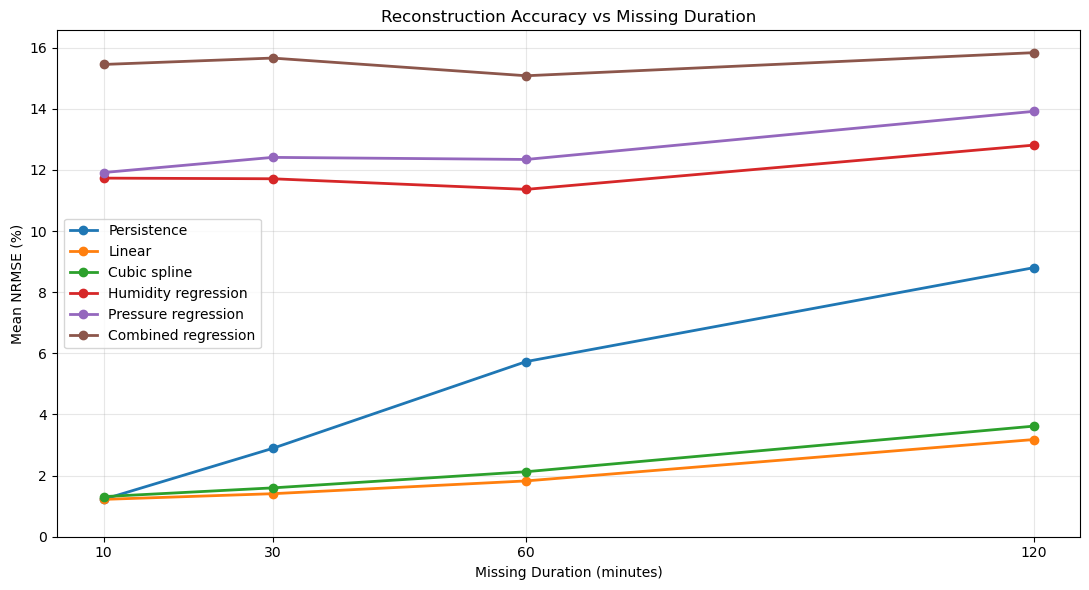

In [54]:
# ============================================================
# Final comparison of six reconstruction methods
# ============================================================

method_order = [
    "Persistence",
    "Linear",
    "Cubic spline",
    "Humidity regression",
    "Pressure regression",
    "Combined regression"
]

plt.figure(figsize=(11, 6))

for method in method_order:

    method_data = (
        final_summary[
            final_summary["method"] == method
        ]
        .sort_values("duration_min")
    )

    plt.plot(
        method_data["duration_min"],
        method_data["NRMSE_mean"],
        marker="o",
        linewidth=2,
        label=method
    )

plt.xlabel("Missing Duration (minutes)")
plt.ylabel("Mean NRMSE (%)")
plt.title("Reconstruction Accuracy vs Missing Duration")

plt.xticks([10, 30, 60, 120])
plt.ylim(bottom=0)

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
figures_dir = Path(project_root) / "results" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "six_method_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [55]:
# ============================================================
# Export Final Validation Results
# ============================================================

from pathlib import Path

# Project directories
tables_dir = Path(project_root) / "results" / "tables"

tables_dir.mkdir(parents=True, exist_ok=True)

# Save artificial missing windows
missing_windows.to_csv(
    tables_dir / "missing_windows.csv",
    index=False
)

# Save detailed results from all 360 evaluations
reconstruction_results.to_csv(
    tables_dir / "six_method_validation_results.csv",
    index=False
)

# Save final mean MAE, RMSE and NRMSE
final_summary.to_csv(
    tables_dir / "six_method_validation_summary.csv",
    index=False
)

# Save regression model comparison
regression_model_comparison.to_csv(
    tables_dir / "regression_model_comparison.csv",
    index=False
)

print("Final results exported successfully!")
print("Saved to:", tables_dir)

Final results exported successfully!
Saved to: /Users/ben/Desktop/MMA3001 project/MMA3001-Occupancy-Prediction/results/tables


In [57]:
# ============================================================
# Endpoint-Constrained Combined Regression
# ============================================================
# ============================================================
# Select a 120-minute missing window for visualisation
# ============================================================

# Select the first 120-minute validation window
chosen_window = missing_windows[
    missing_windows["duration_min"] == 120
].iloc[0]

gap_start = chosen_window["start_time"]
gap_end = chosen_window["end_time"]

# Include 30 minutes of measurements before and after the gap
plot_data = validation_data[
    (validation_data["time"] >= gap_start - pd.Timedelta(minutes=30)) &
    (validation_data["time"] <= gap_end + pd.Timedelta(minutes=30))
].copy()

plot_data = plot_data.sort_values("time").reset_index(drop=True)

print("Gap start:", gap_start)
print("Gap end:", gap_end)

# Use the same gap definition as the validation code
cutoff_time = gap_end - pd.Timedelta(seconds=5)

hidden_mask = (
    (plot_data["time"] >= gap_start) &
    (plot_data["time"] < cutoff_time)
)

# Known temperature measurements on either side of the gap
left = validation_data[
    validation_data["time"] < gap_start
].iloc[-1]

right = validation_data[
    validation_data["time"] >= cutoff_time
].iloc[0]

# Times inside the missing window
gap_times = plot_data.loc[hidden_mask, "time"]

# Original combined regression predictions
X_gap = plot_data.loc[
    hidden_mask, ["humidity", "pressure"]
]

raw_prediction = combined_model.predict(X_gap)

# Regression predictions at the two known endpoints
X_endpoints = pd.DataFrame([
    left[["humidity", "pressure"]],
    right[["humidity", "pressure"]]
])

raw_left, raw_right = combined_model.predict(X_endpoints)

# Actual known boundary temperatures
T_left = float(left["temperature"])
T_right = float(right["temperature"])

# Relative time position between the two endpoints
alpha = (
    (gap_times - left["time"]) /
    (right["time"] - left["time"])
).to_numpy(dtype=float)

# Apply endpoint correction
constrained_prediction = (
    raw_prediction
    + (1 - alpha) * (T_left - raw_left)
    + alpha * (T_right - raw_right)
)

# Include both known endpoints in the plotted curve
constrained_times = (
    [left["time"]]
    + gap_times.tolist()
    + [right["time"]]
)

constrained_temperatures = (
    [T_left]
    + constrained_prediction.tolist()
    + [T_right]
)

Gap start: 2024-05-24 06:55:37
Gap end: 2024-05-24 08:55:37


In [58]:
reconstruction_results = validate_reconstruction(
    validation_data=validation_data,
    missing_windows=missing_windows,
    humidity_model=humidity_model,
    pressure_model=pressure_model,
    combined_model=combined_model,
    temperature_range=temperature_range
)

print("Total evaluations:", len(reconstruction_results))

Total evaluations: 420


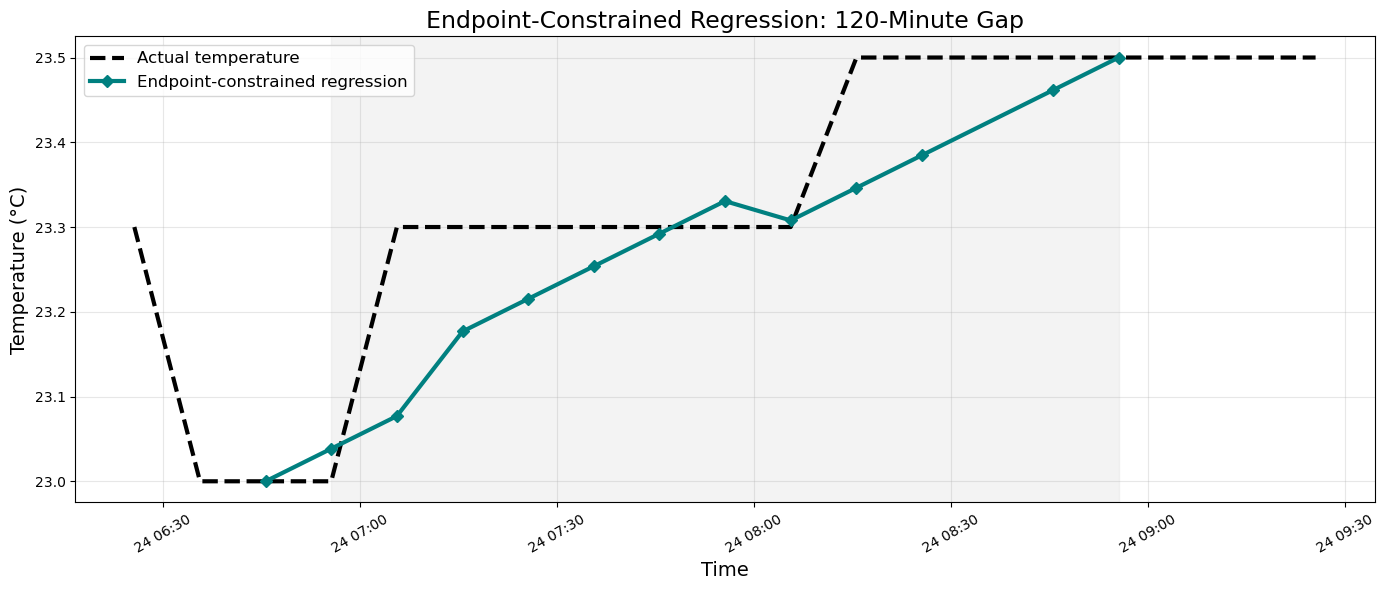

In [59]:
# Preview: Endpoint-Constrained Combined Regression

plt.figure(figsize=(14, 6))

# Actual temperature
plt.plot(
    plot_data["time"],
    plot_data["temperature"],
    color="black",
    linestyle="--",
    linewidth=3,
    label="Actual temperature"
)

# Endpoint-constrained regression
plt.plot(
    constrained_times,
    constrained_temperatures,
    color="teal",
    marker="D",
    markersize=6,
    linewidth=3,
    label="Endpoint-constrained regression"
)

# Missing window
plt.axvspan(
    gap_start,
    gap_end,
    color="lightgray",
    alpha=0.25
)

plt.title("Endpoint-Constrained Regression: 120-Minute Gap", fontsize=17)
plt.xlabel("Time", fontsize=14)
plt.ylabel("Temperature (°C)", fontsize=14)
plt.xticks(rotation=30)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [60]:
# ============================================================
# Seven-Method NRMSE Comparison
# ============================================================

summary_7 = (
    reconstruction_results
    .groupby(["duration_min", "method"])
    .agg(
        n_tests=("RMSE", "size"),
        MAE_mean=("MAE", "mean"),
        RMSE_mean=("RMSE", "mean"),
        NRMSE_mean=("NRMSE (%)", "mean")
    )
    .reset_index()
)

# Display NRMSE (%) for all seven methods
nrmse_table = summary_7.pivot(
    index="method",
    columns="duration_min",
    values="NRMSE_mean"
)

print("Seven-Method NRMSE Comparison (%)")
display(nrmse_table.round(4))

Seven-Method NRMSE Comparison (%)


duration_min,10,30,60,120
method,,,,
Combined regression,15.4526,15.6619,15.0829,15.8383
Cubic spline,1.3119,1.5979,2.1272,3.6176
Endpoint-constrained regression,1.2039,1.4825,1.8920,3.1035
Humidity regression,11.7334,11.7125,11.3655,12.8124
Linear,1.2216,1.4075,1.8261,3.1792
Persistence,1.2222,2.8907,5.7316,8.8016
Pressure regression,11.9157,12.4124,12.3442,13.9177


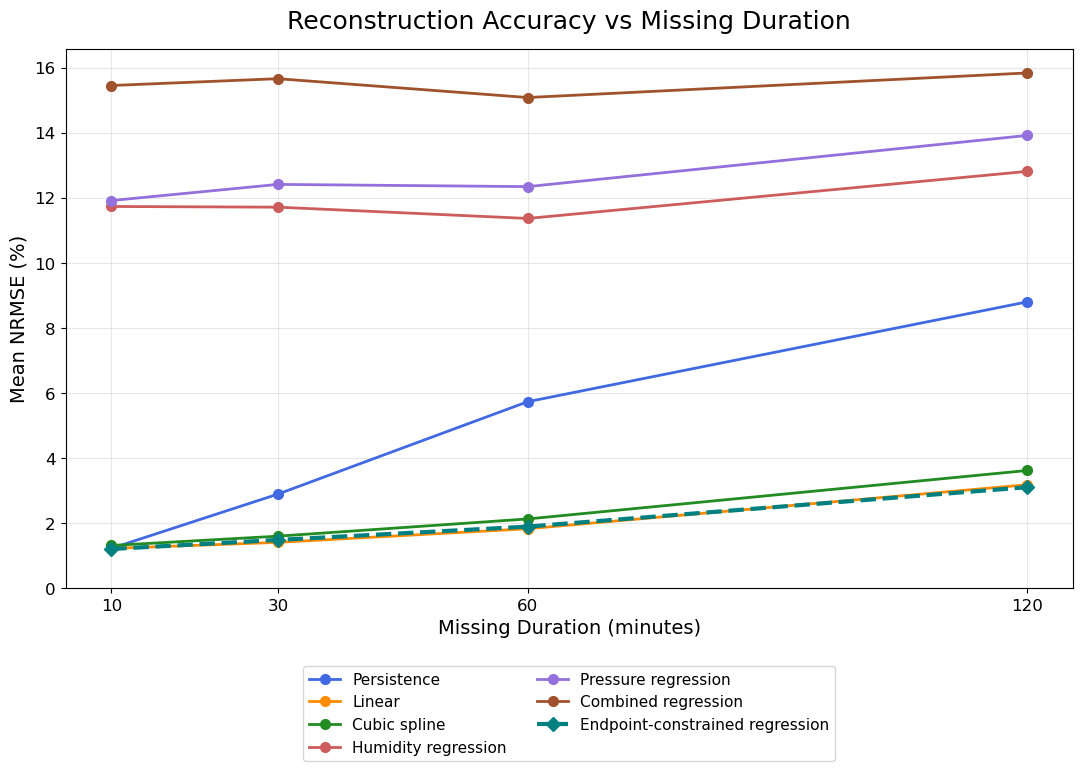

In [61]:
# ============================================================
# Final Seven-Method NRMSE Comparison
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt

method_order = [
    "Persistence",
    "Linear",
    "Cubic spline",
    "Humidity regression",
    "Pressure regression",
    "Combined regression",
    "Endpoint-constrained regression"
]

colors = {
    "Persistence": "royalblue",
    "Linear": "darkorange",
    "Cubic spline": "forestgreen",
    "Humidity regression": "indianred",
    "Pressure regression": "mediumpurple",
    "Combined regression": "sienna",
    "Endpoint-constrained regression": "teal"
}

plt.figure(figsize=(13, 7))

for method in method_order:

    data = summary_7[
        summary_7["method"] == method
    ].sort_values("duration_min")

    plt.plot(
        data["duration_min"],
        data["NRMSE_mean"],
        marker="D" if method == "Endpoint-constrained regression" else "o",
        markersize=7,
        linewidth=3 if method == "Endpoint-constrained regression" else 2,
        linestyle="--" if method == "Endpoint-constrained regression" else "-",
        color=colors[method],
        label=method
    )

plt.title(
    "Reconstruction Accuracy vs Missing Duration",
    fontsize=18,
    pad=15
)

plt.xlabel("Missing Duration (minutes)", fontsize=14)
plt.ylabel("Mean NRMSE (%)", fontsize=14)

plt.xticks([10, 30, 60, 120], fontsize=12)
plt.yticks(fontsize=12)

plt.ylim(bottom=0)
plt.grid(True, alpha=0.3)

plt.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=2,
    fontsize=11
)

# Save new figure
figures_dir = Path(project_root) / "results" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "seven_method_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

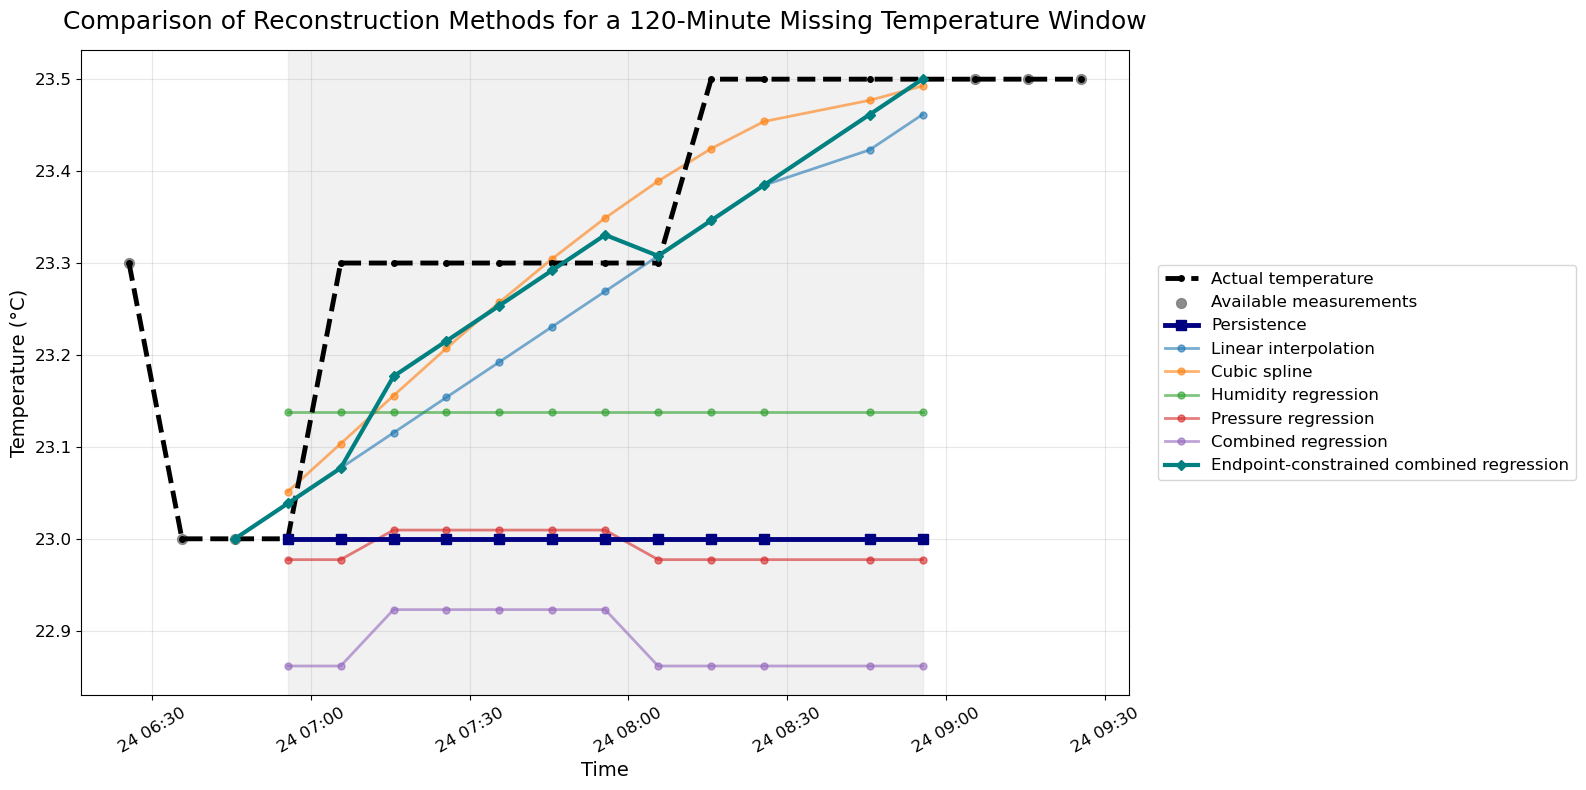

In [62]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

# ============================================================
# Final comparison plot for one 120-minute missing window
# ============================================================

chosen_window = missing_windows[
    (missing_windows["duration_min"] == 120) &
    (missing_windows["test_number"] == 1)
].iloc[0]

gap_start = chosen_window["start_time"]
gap_end = chosen_window["end_time"]

context_before = pd.Timedelta(minutes=30)
context_after = pd.Timedelta(minutes=30)

plot_data = validation_data[
    (validation_data["time"] >= gap_start - context_before) &
    (validation_data["time"] <= gap_end + context_after)
].copy()

plot_data = plot_data.sort_values("time").reset_index(drop=True)

hidden_mask = (plot_data["time"] >= gap_start) & (plot_data["time"] <= gap_end)

actual_temp = plot_data["temperature"].copy()

available_temp = plot_data["temperature"].copy()
available_temp.loc[hidden_mask] = np.nan

# ----------------------------
# Predictions
# ----------------------------

# Persistence
persistence_pred = pd.Series(np.nan, index=plot_data.index)
last_value_before_gap = plot_data.loc[
    plot_data["time"] < gap_start, "temperature"
].iloc[-1]
persistence_pred.loc[hidden_mask] = last_value_before_gap

# Linear interpolation
linear_pred = available_temp.interpolate(method="linear")
linear_gap_only = pd.Series(np.nan, index=plot_data.index)
linear_gap_only.loc[hidden_mask] = linear_pred.loc[hidden_mask]

# Cubic spline
known_idx = np.where(~available_temp.isna())[0]
known_x = known_idx
known_y = available_temp.dropna().values

cs = CubicSpline(known_x, known_y)
cubic_pred = pd.Series(cs(np.arange(len(plot_data))), index=plot_data.index)
cubic_gap_only = pd.Series(np.nan, index=plot_data.index)
cubic_gap_only.loc[hidden_mask] = cubic_pred.loc[hidden_mask]

# Regression
humidity_pred = pd.Series(np.nan, index=plot_data.index)
pressure_pred = pd.Series(np.nan, index=plot_data.index)
combined_pred = pd.Series(np.nan, index=plot_data.index)

humidity_pred.loc[hidden_mask] = humidity_model.predict(
    plot_data.loc[hidden_mask, ["humidity"]]
)

pressure_pred.loc[hidden_mask] = pressure_model.predict(
    plot_data.loc[hidden_mask, ["pressure"]]
)

combined_pred.loc[hidden_mask] = combined_model.predict(
    plot_data.loc[hidden_mask, ["humidity", "pressure"]]
)

# ============================================================
# Better plot
# ============================================================

plt.figure(figsize=(16, 8))

# Actual temperature -> very obvious
plt.plot(
    plot_data["time"],
    actual_temp,
    linestyle="--",
    linewidth=3.5,
    color="black",
    marker="o",
    markersize=4,
    label="Actual temperature",
    zorder=5
)

# Available measurements
plt.scatter(
    plot_data.loc[~hidden_mask, "time"],
    plot_data.loc[~hidden_mask, "temperature"],
    s=50,
    color="gray",
    alpha=0.9,
    label="Available measurements",
    zorder=4
)

# Persistence -> very obvious
plt.plot(
    plot_data["time"],
    persistence_pred,
    marker="s",
    markersize=7,
    linewidth=3.5,
    color="navy",
    label="Persistence",
    zorder=5
)

# Other methods -> lighter / less obvious
plt.plot(
    plot_data["time"],
    linear_gap_only,
    marker="o",
    markersize=5,
    linewidth=2,
    alpha=0.6,
    label="Linear interpolation",
    zorder=2
)

plt.plot(
    plot_data["time"],
    cubic_gap_only,
    marker="o",
    markersize=5,
    linewidth=2,
    alpha=0.6,
    label="Cubic spline",
    zorder=2
)

plt.plot(
    plot_data["time"],
    humidity_pred,
    marker="o",
    markersize=5,
    linewidth=2,
    alpha=0.6,
    label="Humidity regression",
    zorder=2
)

plt.plot(
    plot_data["time"],
    pressure_pred,
    marker="o",
    markersize=5,
    linewidth=2,
    alpha=0.6,
    label="Pressure regression",
    zorder=2
)

plt.plot(
    plot_data["time"],
    combined_pred,
    marker="o",
    markersize=5,
    linewidth=2,
    alpha=0.6,
    label="Combined regression",
    zorder=2
)
plt.plot(
    constrained_times,
    constrained_temperatures,
    color="teal",
    linewidth=3,
    marker="D",
    markersize=5,
    label="Endpoint-constrained combined regression",
    zorder=6
)
# Missing window shading
plt.axvspan(gap_start, gap_end, color="lightgray", alpha=0.3)

plt.title(
    "Comparison of Reconstruction Methods for a 120-Minute Missing Temperature Window",
    fontsize=18,
    pad=15
)
plt.xlabel("Time", fontsize=14)
plt.ylabel("Temperature (°C)", fontsize=14)
plt.xticks(rotation=30, fontsize=12)
plt.yticks(fontsize=12)
plt.grid(True, alpha=0.3)

plt.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=12,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    "../results/figures/seven_method_reconstruction_120min.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [63]:
# ============================================================
# Export Final Seven-Method Results
# ============================================================

from pathlib import Path

tables_dir = Path(project_root) / "results" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)

# Save 60 missing windows
missing_windows.to_csv(
    tables_dir / "missing_windows.csv",
    index=False
)

# Save 420 method-window evaluations
reconstruction_results.to_csv(
    tables_dir / "seven_method_validation_results.csv",
    index=False
)

# Save final MAE, RMSE and NRMSE summary
summary_7.to_csv(
    tables_dir / "seven_method_validation_summary.csv",
    index=False
)

# Verify final results
assert len(missing_windows) == 60
assert len(reconstruction_results) == 420
assert reconstruction_results["method"].nunique() == 7

print("Final seven-method results exported successfully!")
print("60 windows, 7 methods, 420 evaluations")

Final seven-method results exported successfully!
60 windows, 7 methods, 420 evaluations


In [ ]:
import time
import numpy as np
import pandas as pd
from scipy.interpolate import CubicSpline

# Prepare identical inputs for all benchmarked methods
benchmark_windows = []

for _, window in missing_windows.iterrows():
    start_time = window["start_time"]
    cutoff_time = window["end_time"] - pd.Timedelta(seconds=5)

    hidden = validation_data[
        (validation_data["time"] >= start_time) &
        (validation_data["time"] < cutoff_time)
    ]

    before = validation_data[
        validation_data["time"] < start_time
    ].tail(4)

    after = validation_data[
        validation_data["time"] >= cutoff_time
    ].head(4)

    if len(hidden) == 0 or len(before) < 4 or len(after) < 4:
        continue

    known = pd.concat([before, after]).sort_values("time")

    x_known = (known["time"] - start_time).dt.total_seconds().to_numpy()
    x_hidden = (hidden["time"] - start_time).dt.total_seconds().to_numpy()
    y_known = known["temperature"].to_numpy()

    t_left = (before["time"].iloc[-1] - start_time).total_seconds()
    t_right = (after["time"].iloc[0] - start_time).total_seconds()

    alpha = (x_hidden - t_left) / (t_right - t_left)

    benchmark_windows.append({
        "x_known": x_known,
        "x_hidden": x_hidden,
        "y_known": y_known,
        "X_hidden": hidden[["humidity", "pressure"]],
        "X_left": before.tail(1)[["humidity", "pressure"]],
        "X_right": after.head(1)[["humidity", "pressure"]],
        "T_left": before["temperature"].iloc[-1],
        "T_right": after["temperature"].iloc[0],
        "alpha": alpha
    })

assert len(benchmark_windows) == 60, "Expected 60 validation windows."

# Reconstruct using the same mathematical approaches
def benchmark_prediction(method, w):

    if method == "Linear interpolation":
        return np.interp(
            w["x_hidden"], w["x_known"], w["y_known"]
        )

    if method == "Cubic spline":
        spline = CubicSpline(
            w["x_known"], w["y_known"], bc_type="natural"
        )
        return spline(w["x_hidden"])

    if method == "Combined regression":
        return combined_model.predict(w["X_hidden"])

    if method == "Endpoint-constrained regression":
        raw = combined_model.predict(w["X_hidden"])
        left_pred = combined_model.predict(w["X_left"])[0]
        right_pred = combined_model.predict(w["X_right"])[0]

        return (
            raw
            + (1 - w["alpha"]) * (w["T_left"] - left_pred)
            + w["alpha"] * (w["T_right"] - right_pred)
        )

    raise ValueError("Unknown method")

# Benchmark reconstruction computation only
methods = [
    "Linear interpolation",
    "Cubic spline",
    "Combined regression",
    "Endpoint-constrained regression"
]

runtime_results = []

for method in methods:

    # Warm-up
    for w in benchmark_windows:
        benchmark_prediction(method, w)

    repeated_times = []

    for _ in range(20):
        start = time.perf_counter()

        for w in benchmark_windows:
            benchmark_prediction(method, w)

        elapsed_ms = (time.perf_counter() - start) * 1000
        repeated_times.append(elapsed_ms)

    median_ms = np.median(repeated_times)

    runtime_results.append({
        "Method": method,
        "Median runtime (ms / 60 windows)": median_ms,
        "Runtime per window (ms)": median_ms / 60
    })

runtime_table = pd.DataFrame(runtime_results).round(4)

runtime_table


,Method,Median runtime (ms / 60 windows),Runtime per window (ms)
0,Linear interpolation,0.0659,0.0011
1,Cubic spline,5.3577,0.0893
2,Combined regression,18.7317,0.3122
3,Endpoint-constrained regression,53.4988,0.8916


In [65]:
runtime_table.to_csv(
    "../results/tables/runtime_comparison.csv",
    index=False
)

In [66]:
from pathlib import Path
import pandas as pd

# Locate the results folder
tables_dir = Path("../results/tables")

if not tables_dir.exists():
    tables_dir = Path("results/tables")

# Create the original six-method results
for kind, expected_rows in [
    ("results", 360),
    ("summary", 24)
]:

    seven = pd.read_csv(
        tables_dir / f"seven_method_validation_{kind}.csv"
    )

    six = seven[
        seven["method"] != "Endpoint-constrained regression"
    ].copy()

    # Check that only the original six methods remain
    assert six["method"].nunique() == 6
    assert len(six) == expected_rows

    output = tables_dir / f"six_method_validation_{kind}.csv"

    six.to_csv(output, index=False)

    print(f"Saved: {output}")
    print(f"Rows: {len(six)} | Methods: {six['method'].nunique()}")

Saved: ../results/tables/six_method_validation_results.csv
Rows: 360 | Methods: 6
Saved: ../results/tables/six_method_validation_summary.csv
Rows: 24 | Methods: 6
